### Import Dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
import matplotlib.collections
import matplotlib.cm as cm

BERLIN_CMAP = cm.get_cmap('berlin')

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import KFold

# ML Models
from sklearn.ensemble import (
    VotingRegressor,
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    BaggingRegressor
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.base import clone

from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

C:\Users\SONALIKA\AppData\Local\Temp\ipykernel_14984\1868656454.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  BERLIN_CMAP = cm.get_cmap('berlin')


### TGA Data Setting

In [2]:
DATA_PATH = r"C:\Users\SONALIKA\Downloads\WSB_TGA_data\WSB_TGA_data\Datasets"

# Training particle-size bins (used to fit the models)
train_sizes = ['w2', 'w3', 'w4']

# Heating rates used for training/testing
heating_rates = [10, 20, 30, 50]

# Completely unseen test particle-size bin
TEST_SIZE = 'w5'

SIZE_MAP = {
    'w2': 150,
    'w3': 250,
    'w4': 350,
    'w5': 450,
}

print("Data directory:")
print(DATA_PATH)

print("\nTrain sizes:", train_sizes)
print("Test size (unseen):", TEST_SIZE)
print("Heating rates:", heating_rates)

Data directory:
C:\Users\SONALIKA\Downloads\WSB_TGA_data\WSB_TGA_data\Datasets

Train sizes: ['w2', 'w3', 'w4']
Test size (unseen): w5
Heating rates: [10, 20, 30, 50]


### Load TGA file

In [3]:
def load_tga_file(size, heating_rate, data_path=DATA_PATH):
    
    filename = os.path.join(data_path, f"{size}@{heating_rate}.csv")

    raw = pd.read_csv(filename)

    df = pd.DataFrame({
        'Ts': raw['Sample Temperature'],      # Sample Temp, NOT Program Temp
        't': raw['Time'],
        'HF': raw['Unsubtracted Heat Flow'],
        'Weight': raw['Unsubtracted Weight'],
        'Tr': raw['Program Temperature'],     # closest walnut equivalent to guava's Tr
    })

    df = df.sort_values('Ts').drop_duplicates('Ts').reset_index(drop=True)
    df['Index'] = np.arange(len(df))

    # mass % relative to the mean of the first 10 rows
    # (same convention already used in your walnut exploration notebook)
    df['mass_percent'] = df['Weight'] / df['Weight'].iloc[:10].mean() * 100

    df['size'] = SIZE_MAP[size]
    df['heating_rate'] = heating_rate

    return df[['Index', 'Ts', 't', 'HF', 'Weight', 'Tr',
               'mass_percent', 'size', 'heating_rate']]

### Resampling each curve to a common length

In [4]:
def resample_tga_curve(df, target_rows):
    df = df.sort_values('Ts').drop_duplicates('Ts').reset_index(drop=True)

    old_Ts = df.Ts.values
    new_Ts = np.linspace(old_Ts.min(), old_Ts.max(), target_rows)

    new_df = pd.DataFrame({'Ts': new_Ts})

    for col in ['t','HF','Weight','Tr','mass_percent']:
        new_df[col] = np.interp(new_Ts, old_Ts, df[col].values)

    new_df['size'] = df['size'].iloc[0]
    new_df['heating_rate'] = df['heating_rate'].iloc[0]
    new_df['Index'] = np.arange(target_rows)

    return new_df[
        ['Index','Ts','t','HF','Weight','Tr',
         'mass_percent','size','heating_rate']
    ].reset_index(drop=True)

### Load Training + Test data (w2, w3, w4, w5), then resample to a common row count

In [5]:
print("="*50)
print("LOADING RAW CURVES (w2, w3, w4, w5)")

train_raw = []
for size in train_sizes:
    for rate in heating_rates:
        df = load_tga_file(size, rate)
        print(f"{size}@{rate}.csv -> Rows: {len(df)}")
        train_raw.append(df)

test_raw = []
for rate in heating_rates:
    try:
        df = load_tga_file(TEST_SIZE, rate)
    except FileNotFoundError:
        print(f"Skipped: {TEST_SIZE}@{rate}.csv (not found)")
        continue
    print(f"{TEST_SIZE}@{rate}.csv -> Rows: {len(df)}")
    test_raw.append(df)

if not test_raw:
    raise ValueError(f"No {TEST_SIZE} test files were loaded.")

all_lengths = [len(df) for df in train_raw + test_raw]
TARGET_ROWS = min(all_lengths)
print(f"\nSmallest curve has {TARGET_ROWS} rows -> resampling everything to {TARGET_ROWS} points")


train_dfs = [resample_tga_curve(df, TARGET_ROWS) for df in train_raw]
train_data = pd.concat(train_dfs, ignore_index=True)

test_dfs = [resample_tga_curve(df, TARGET_ROWS) for df in test_raw]
test_data = pd.concat(test_dfs, ignore_index=True)

print("\n" + "="*50)
print(f"Training data : {len(train_dfs)} curves x {TARGET_ROWS} rows = {len(train_data)} total rows")
print(f"{TEST_SIZE} test data  : {len(test_dfs)} curves x {TARGET_ROWS} rows = {len(test_data)} total rows")

LOADING RAW CURVES (w2, w3, w4, w5)
w2@10.csv -> Rows: 40240
w2@20.csv -> Rows: 20707
w2@30.csv -> Rows: 13808
w2@50.csv -> Rows: 8260
w3@10.csv -> Rows: 40363
w3@20.csv -> Rows: 20721
w3@30.csv -> Rows: 13810
w3@50.csv -> Rows: 8262
w4@10.csv -> Rows: 40382
w4@20.csv -> Rows: 20714
w4@30.csv -> Rows: 13811
w4@50.csv -> Rows: 8262
w5@10.csv -> Rows: 40444
w5@20.csv -> Rows: 20709
w5@30.csv -> Rows: 13813
w5@50.csv -> Rows: 8273

Smallest curve has 8260 rows -> resampling everything to 8260 points

Training data : 12 curves x 8260 rows = 99120 total rows
w5 test data  : 4 curves x 8260 rows = 33040 total rows


### Verify Sampling

In [6]:
print("\nTRAINING CURVES")
print(train_data.groupby(['size', 'heating_rate']).size())

print(f"\n{TEST_SIZE} TEST CURVES")
print(test_data.groupby(['size', 'heating_rate']).size())


TRAINING CURVES
size  heating_rate
150   10              8260
      20              8260
      30              8260
      50              8260
250   10              8260
      20              8260
      30              8260
      50              8260
350   10              8260
      20              8260
      30              8260
      50              8260
dtype: int64

w5 TEST CURVES
size  heating_rate
450   10              8260
      20              8260
      30              8260
      50              8260
dtype: int64


## Grouped Statistical Violin Plots

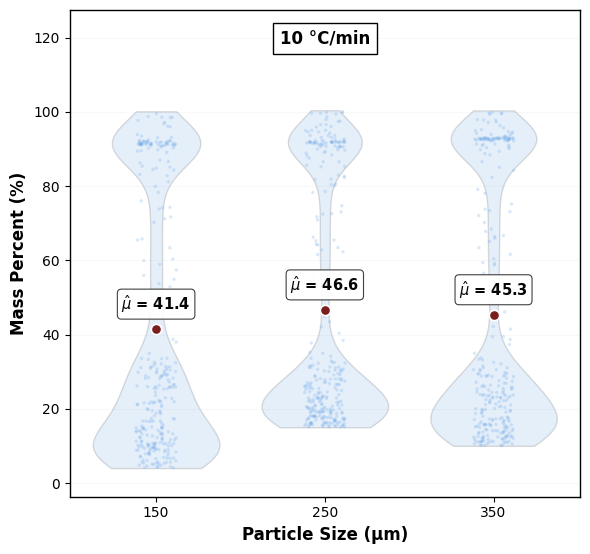

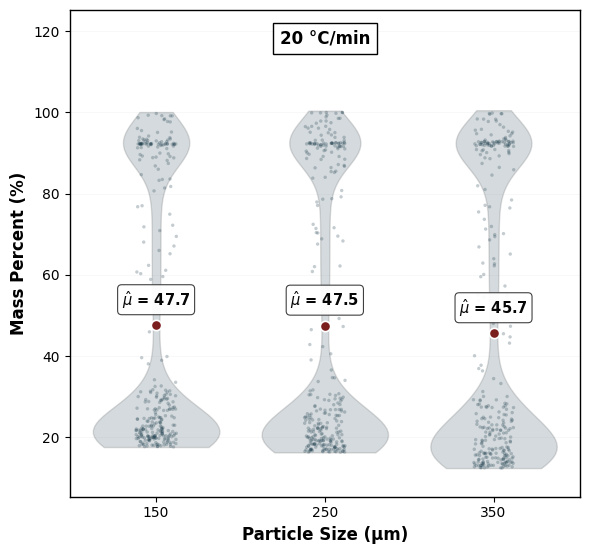

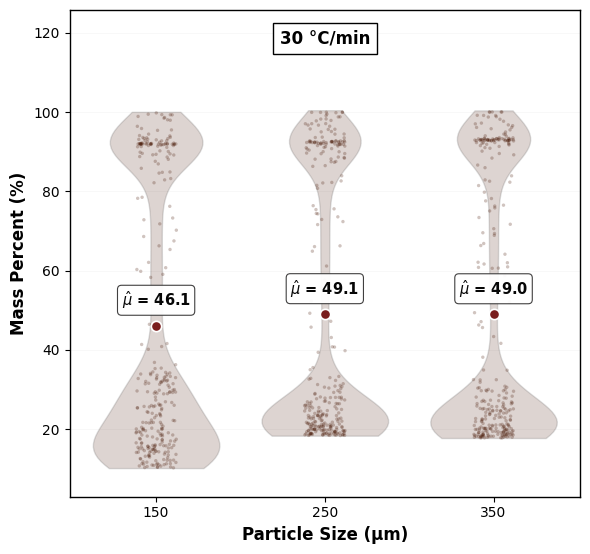

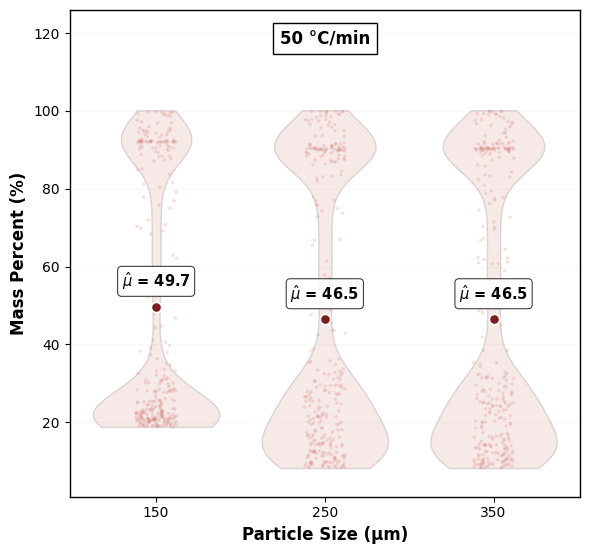

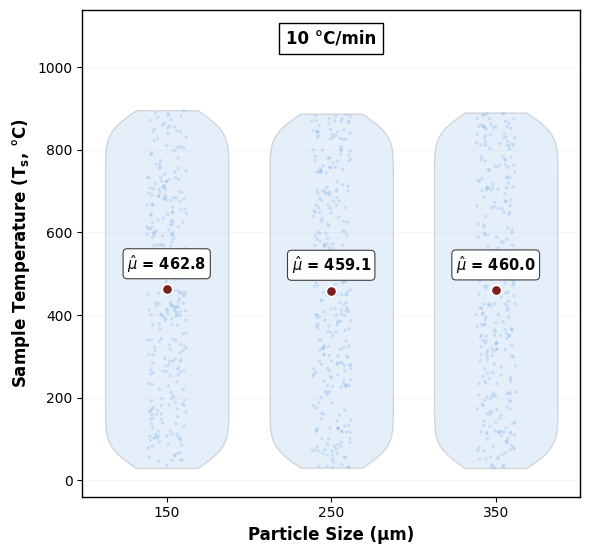

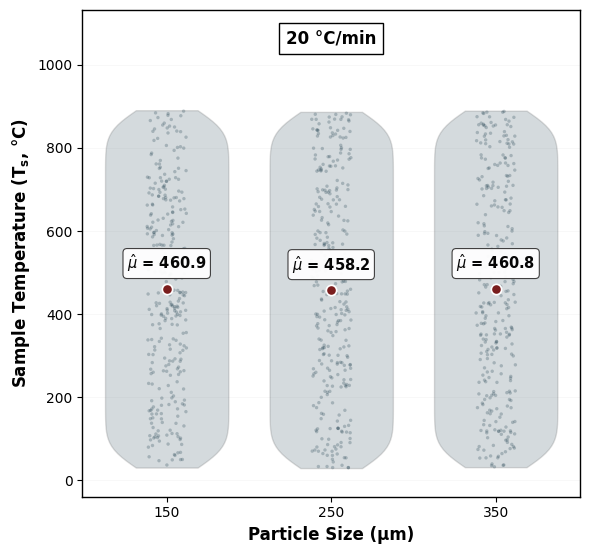

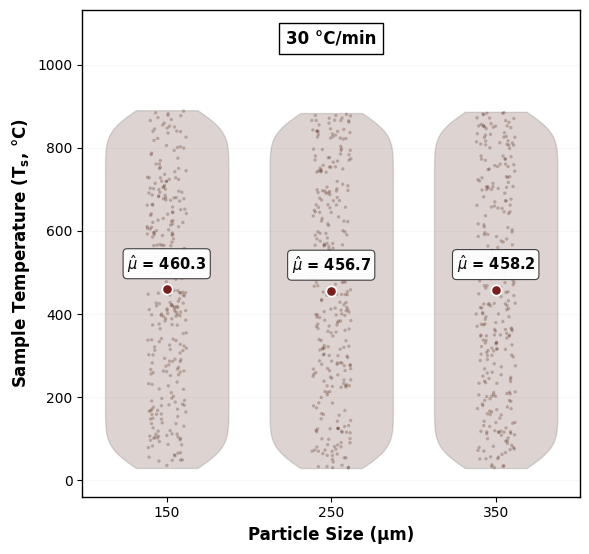

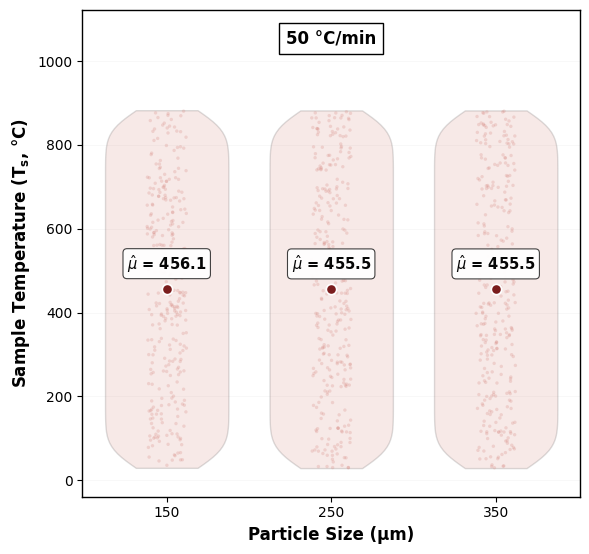

In [7]:
plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.edgecolor': '#555555',
    'axes.linewidth': 0.8,
})

colors = [BERLIN_CMAP(x) for x in np.linspace(0.08, 0.92, len(heating_rates))]

for feature in ['mass_percent', 'Ts']:
    for rate, c in zip(heating_rates, colors):
        fig, a = plt.subplots(figsize=(6, 6))

        a.grid(axis='y', alpha=.35, color='#ececec', linewidth=0.7)
        a.set_axisbelow(True)

        d = train_data[train_data.heating_rate == rate]
        sizes_present = sorted(d['size'].unique())
        data_by_size = [d[d['size'] == s][feature].values for s in sizes_present]
        positions = np.arange(1, len(sizes_present) + 1)

        all_vals = np.concatenate(data_by_size)
        ymin, ymax = all_vals.min(), all_vals.max()
        yrange = ymax - ymin if ymax > ymin else 1
        pad_top = yrange * 0.28
        pad_bot = yrange * 0.08

        vp = a.violinplot(
            data_by_size, positions=positions,
            showmeans=False, showextrema=False, showmedians=False,
            widths=0.75
        )
        for body in vp['bodies']:
            body.set_facecolor(c)
            body.set_edgecolor('#444444')
            body.set_linewidth(1.0)
            body.set_alpha(0.18)

        rng = np.random.default_rng(42)
        max_points = 300   # cap points drawn per group so dense raw curves don't smear into a solid block
        for pos, vals in zip(positions, data_by_size):
            if len(vals) > max_points:
                vals_plot = rng.choice(vals, size=max_points, replace=False)
            else:
                vals_plot = vals
            jitter = rng.uniform(-0.12, 0.12, size=len(vals_plot))
            a.scatter(pos + jitter, vals_plot, s=6, color=c, alpha=0.25,
                      edgecolor='none', zorder=2)

        for pos, vals in zip(positions, data_by_size):
            mu = np.mean(vals)
            a.scatter(pos, mu, s=55, color='#7A1E1E', zorder=4,
                      edgecolor='white', linewidth=1.2)
            a.annotate(
                f'$\\hat{{\\mu}}$ = {mu:.1f}',
                (pos, mu), textcoords='offset points', xytext=(0, 14),
                ha='center', fontsize=10.5, fontweight='bold', color="#060606",
                bbox=dict(boxstyle='round,pad=0.28', facecolor='white',
                         edgecolor="#373636", linewidth=0.8, alpha=0.95),
                zorder=5
            )

        a.text(
            .5, .96,
            f'{rate} °C/min',
            transform=a.transAxes,
            fontsize=12,
            fontweight='bold',
            ha='center', va='top',
            bbox=dict(boxstyle='square,pad=0.4', facecolor='white',
                      edgecolor='black', linewidth=1.0)
        )

        a.set_ylim(ymin - pad_bot, ymax + pad_top)

        a.set_xticks(positions)
        a.set_xticklabels([f'{s}' for s in sizes_present])
        a.set_xlabel('Particle Size (µm)', fontsize=12, fontweight='bold')
        ylabel_map = {'mass_percent': 'Mass Percent (%)',
                      'Ts': 'Sample Temperature ($\mathbf{T_s}$, °C)'}
        a.set_ylabel(ylabel_map.get(feature, feature.replace('_', ' ').title()), fontsize=12, fontweight='bold')

        for spine in a.spines.values():
            spine.set_visible(True)
            spine.set_color('black')
            spine.set_linewidth(1.0)

        plt.tight_layout(rect=[0, 0, 1, 0.94])
        plt.show()
        plt.close()

### Train Models

In [8]:
features = ['Ts', 'size', 'heating_rate']   # raw, predictable-at-inference columns only
target = 'mass_percent'

X = train_data[features]
y = train_data[target]

print("Features:", list(X.columns))
print(f"X: {X.shape}, y: {y.shape}")

models = {
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'LinearRegression': LinearRegression(),
    'DecisionTreeRegressor': DecisionTreeRegressor(random_state=42),
    'RandomForestRegressor': RandomForestRegressor(random_state=42, n_jobs=1),
    'ExtraTreesRegressor': ExtraTreesRegressor(random_state=42, n_jobs=1),
    'GradientBoostingRegressor': GradientBoostingRegressor(random_state=42),
    'AdaBoostRegressor': AdaBoostRegressor(random_state=42),
    'KNeighborsRegressor': KNeighborsRegressor(n_jobs=-1),
    'CatBoostRegressor': CatBoostRegressor(random_state=42, verbose=0)
}

models['VotingEnsemble'] = VotingRegressor(
    estimators=list(models.items())
)

print(f"\nTotal models: {len(models)}")

Features: ['Ts', 'size', 'heating_rate']
X: (99120, 3), y: (99120,)

Total models: 11


### Leave-One-Group-Out CV (grouped by size + heating rate)

In [9]:
from sklearn.model_selection import LeaveOneGroupOut

# --- WITHOUT FEATURE ENGINEERING (raw columns only) ---
features = ['Ts', 'size', 'heating_rate']
target = 'mass_percent'

X = train_data[features]
y = train_data[target]

# --- DEFINE GROUPS (size + heating_rate combined) ---
groups = train_data["size"].astype(str) + "_" + train_data["heating_rate"].astype(str)
logo = LeaveOneGroupOut()

print(f"--- Executing LOGO CV | Unique groups (size+heating_rate): {groups.nunique()} ---")
for train_idx, test_idx in logo.split(X, y, groups=groups):
    held_out_group = groups.iloc[test_idx].unique()
    
results = []
predictions_store = {}
best_logo_mae = float("inf")
best_model_name = ""
best_model_instance = None

print("\n--- Running CV per model ---")

for name, model in models.items():
    try:
        y_true_all = []
        y_pred_all = []

        for train_idx, test_idx in logo.split(X, y, groups=groups):
            X_train, X_test_logo = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test_logo = y.iloc[train_idx], y.iloc[test_idx]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test_logo)

            y_true_all.extend(y_test_logo)
            y_pred_all.extend(y_pred)

        mae = mean_absolute_error(y_true_all, y_pred_all)
        r2 = r2_score(y_true_all, y_pred_all)
        rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
        results.append({"Model": name, "MAE": mae, "R2": r2, "RMSE": rmse})

        predictions_store[name] = {
            "y_true": y_true_all,
            "y_pred": y_pred_all,
            "r2": r2,
            "mae": mae,
            "RMSE": rmse,
            "error": None
        }

        if mae < best_logo_mae:
            best_logo_mae = mae
            best_model_name = name
            best_model_instance = model

    except Exception as e:
        print(f"{name} failed in LeaveOneGroupOut CV: {e}")
        predictions_store[name] = {"error": str(e)}

results_df = pd.DataFrame(results).sort_values(by="MAE", ascending=True)
print(results_df)
print(f"\n\u2605 Champion Model from LOGO CV: {best_model_name} (MAE = {best_logo_mae:.4f}) \u2605")
print(f"\nRetraining {best_model_name} on the FULL training set...")
best_model_instance.fit(X, y)


--- Executing LOGO CV | Unique groups (size+heating_rate): 12 ---

--- Running CV per model ---
                        Model        MAE        R2       RMSE
5         ExtraTreesRegressor   2.323619  0.989055   3.496054
8         KNeighborsRegressor   2.657540  0.985863   3.973350
3       DecisionTreeRegressor   2.661265  0.985966   3.958817
4       RandomForestRegressor   2.692880  0.985842   3.976328
6   GradientBoostingRegressor   2.819907  0.986325   3.907821
7           AdaBoostRegressor   2.820385  0.988881   3.523728
9           CatBoostRegressor   2.966717  0.983510   4.291251
10             VotingEnsemble   4.110684  0.977616   4.999673
1                       Lasso  10.707934  0.854569  12.743918
0                       Ridge  10.709680  0.854537  12.745332
2            LinearRegression  10.709680  0.854537  12.745332

★ Champion Model from LOGO CV: ExtraTreesRegressor (MAE = 2.3236) ★

Retraining ExtraTreesRegressor on the FULL training set...


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


### Models Parity Plots

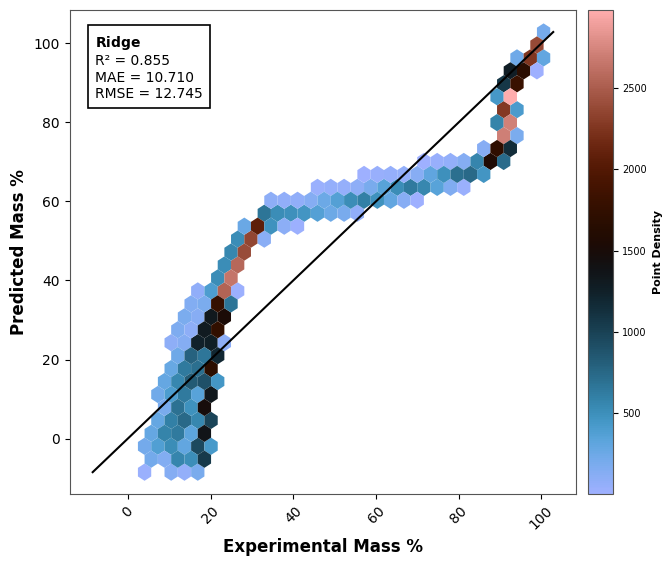

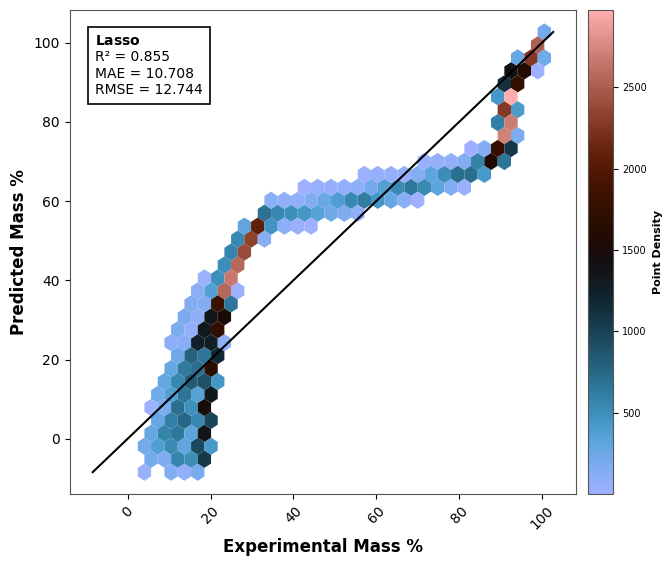

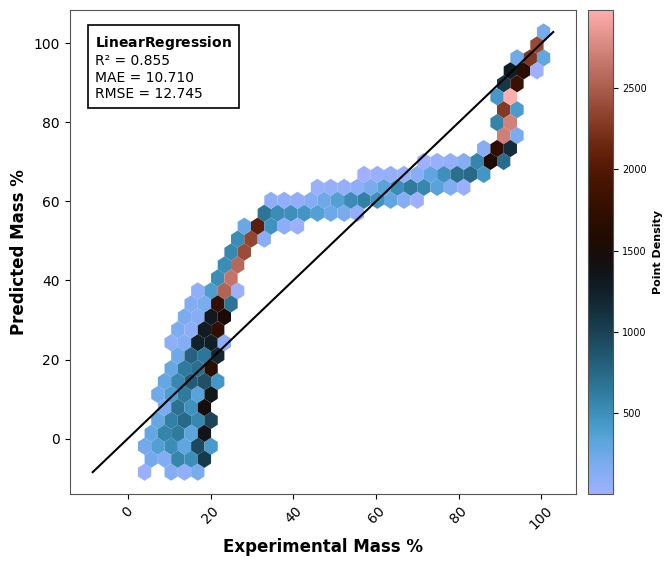

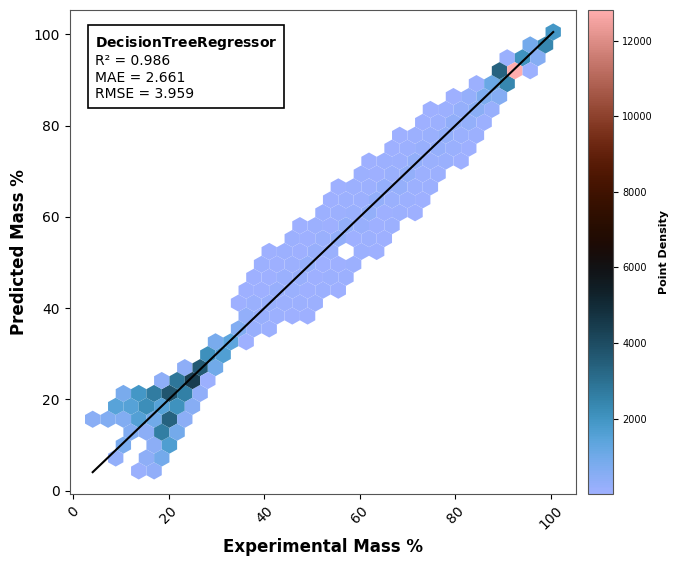

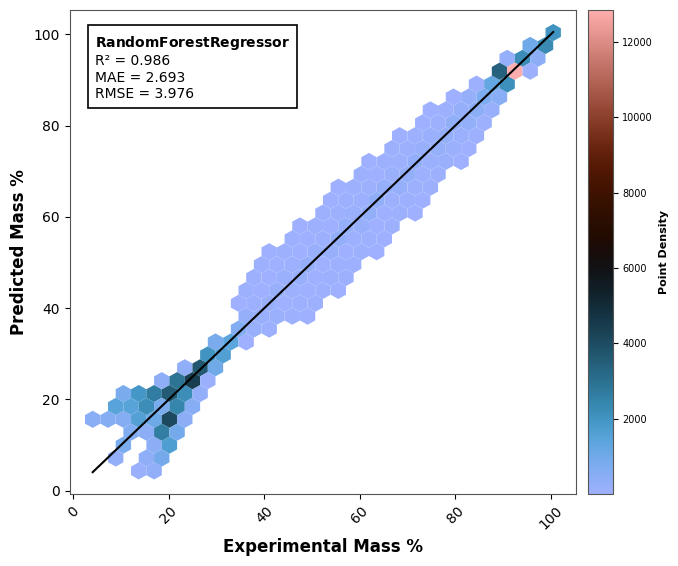

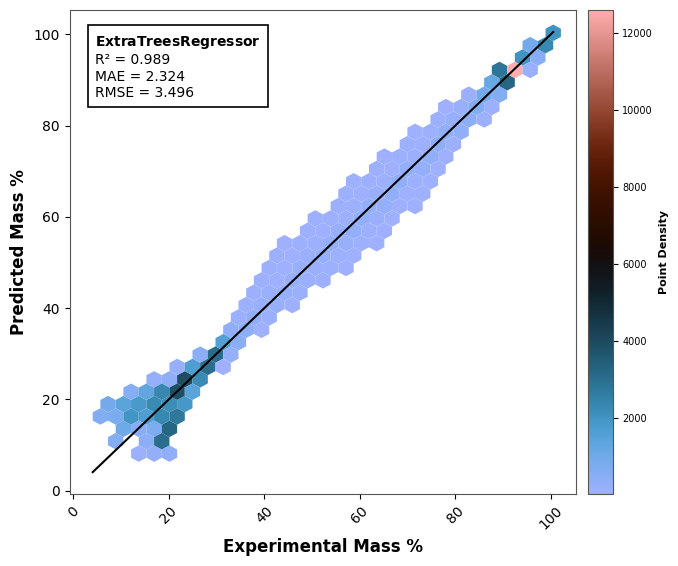

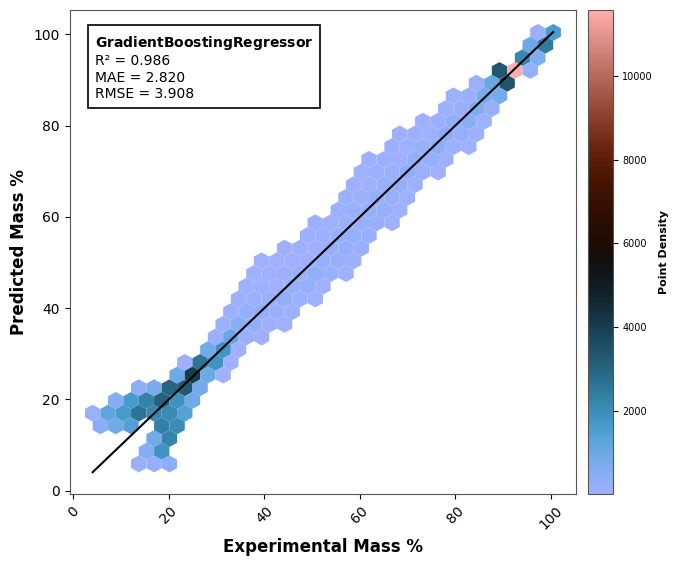

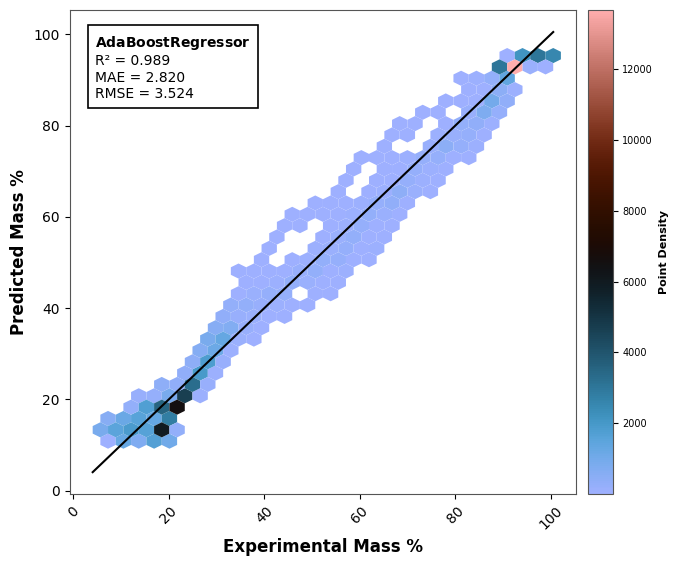

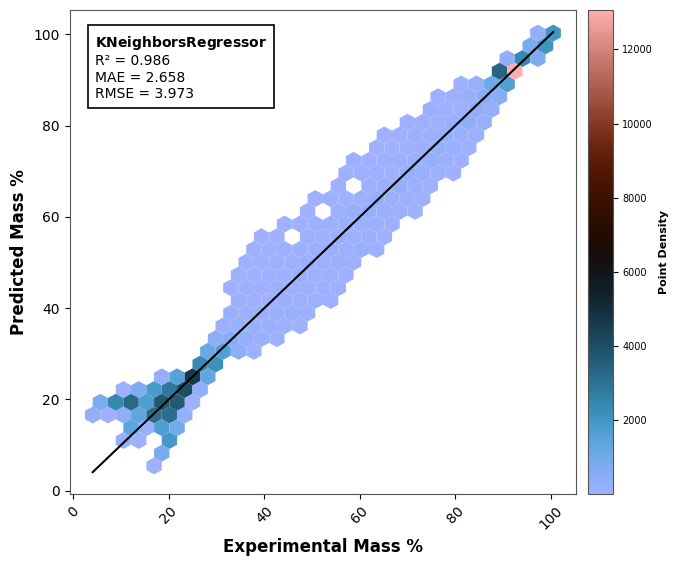

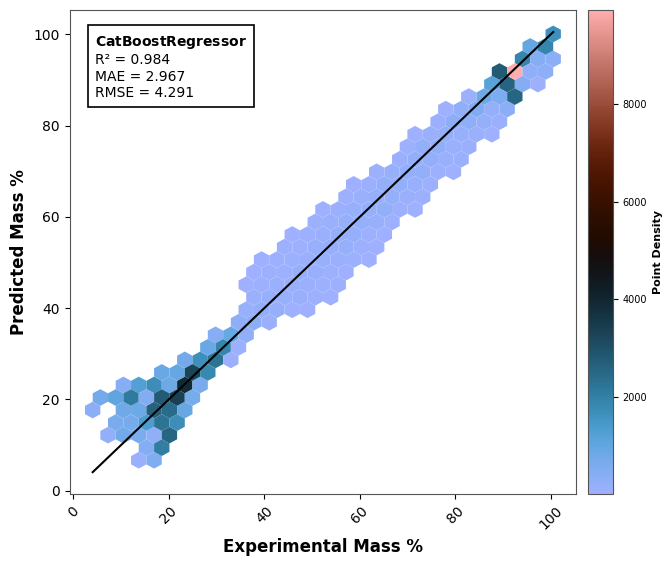

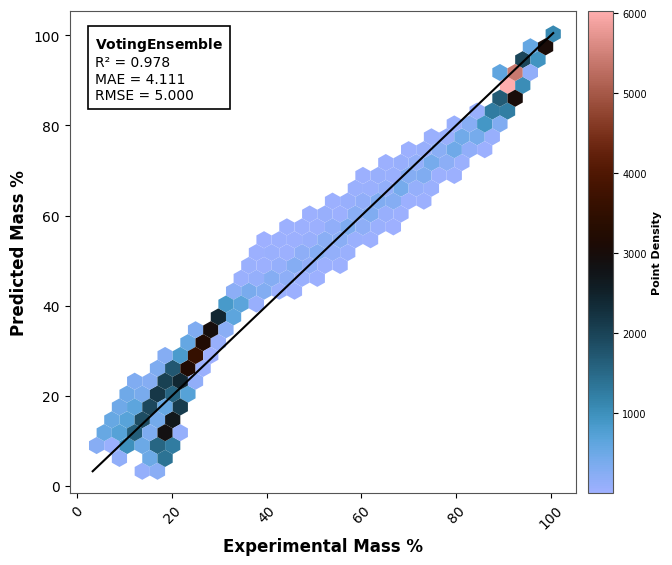

In [10]:
import matplotlib.pyplot as plt

def plot_density_parity_subplot(fig, ax, y_true, y_pred, model_name, r2, mae, rmse):
    hb = ax.hexbin(y_true, y_pred, gridsize=30, cmap=BERLIN_CMAP, mincnt=1, edgecolors='none')
    cbar = fig.colorbar(hb, ax=ax, pad=0.02)
    cbar.set_label('Point Density', fontweight='bold', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    min_val = min(min(y_true), min(y_pred))
    max_val = max(max(y_true), max(y_pred))

    ax.plot([min_val, max_val], [min_val, max_val], color="#010101", linewidth=1.5)
    ax.set_xlabel('Experimental Mass %', fontweight='bold', fontsize=12)
    ax.set_ylabel('Predicted Mass %', fontweight='bold', fontsize=12)
    ax.tick_params(axis='x', labelrotation=45, labelsize=10)
    ax.tick_params(axis='y', labelsize=10)

    text_str = (
        rf'$\mathbf{{{model_name}}}$' +
        f'\nR\u00b2 = {r2:.3f}\nMAE = {mae:.3f}\nRMSE = {rmse:.3f}'
    )

    ax.text(
        0.05, 0.95, text_str,
        transform=ax.transAxes,
        fontsize=10,
        fontweight='normal',
        verticalalignment='top',
        bbox=dict(
            boxstyle='square,pad=0.5',
            facecolor='white',
            edgecolor='black',
            linewidth=1.2
        )
    )
    ax.grid(False)

for name, data in predictions_store.items():
    fig, ax = plt.subplots(figsize=(7, 6))
    fig.patch.set_facecolor('white')

    if data.get("error") is not None:
        ax.text(0.05, 0.95, f"{name} (Error)\nError: {data['error']}",
                transform=ax.transAxes, ha='left', va='top',
                color='red', fontsize=8, fontweight='bold')
        ax.set_title("")
    else:
        plot_density_parity_subplot(fig, ax, data["y_true"], data["y_pred"],
                                     name, data["r2"], data["mae"], data["RMSE"])

    plt.tight_layout(rect=[0, 0.02, 1, 0.98])
    plt.show()
    plt.close()

### TGA Profile

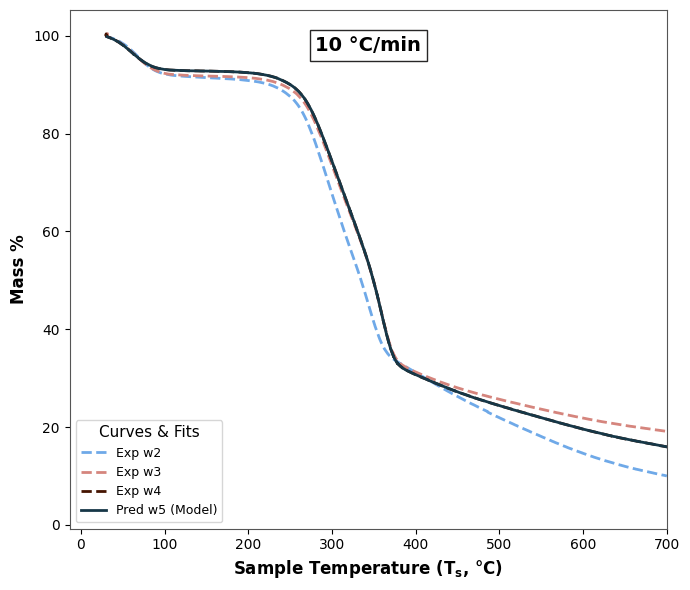

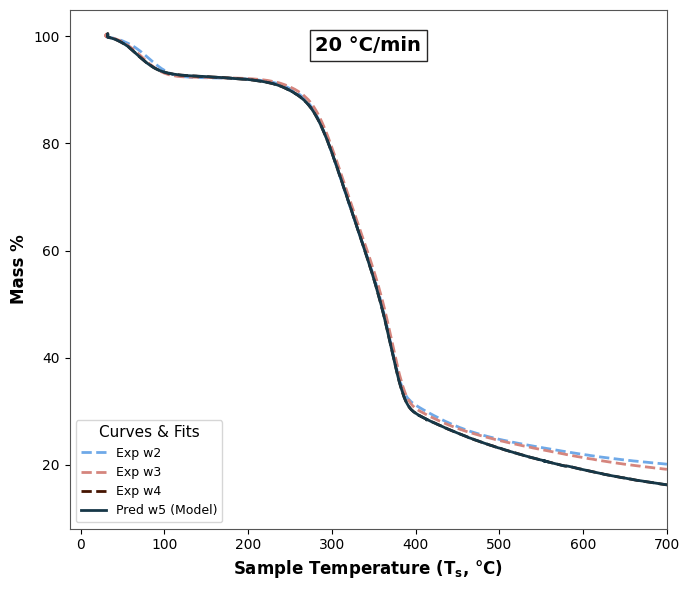

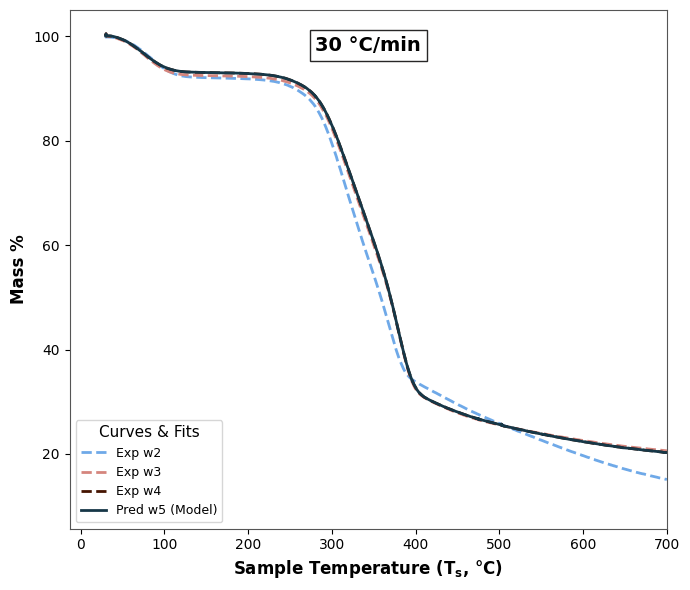

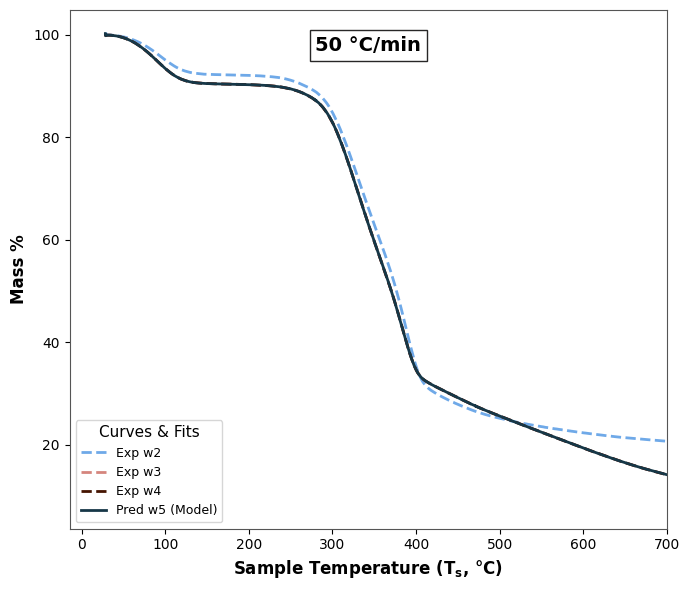

In [11]:
_berlin_vals = np.linspace(0.08, 0.92, 4)
colors_size = {
    'w2': BERLIN_CMAP(_berlin_vals[0]),
    'w3': BERLIN_CMAP(_berlin_vals[3]),
    'w4': BERLIN_CMAP(_berlin_vals[2]),
    'w5': BERLIN_CMAP(_berlin_vals[1]),   # reserved for the held-out prediction
}

for rate in heating_rates:
    fig, ax = plt.subplots(figsize=(7, 6))
    fig.patch.set_facecolor('white')

    for size in train_sizes:
        curve = train_data[
            (train_data['size'] == SIZE_MAP[size]) &
            (train_data['heating_rate'] == rate)
        ]
        if not curve.empty:
            ax.plot(curve['Ts'], curve['mass_percent'],
                    label=f'Exp {size}',
                    color=colors_size.get(size, '#000000'),
                    linewidth=2.0,
                    linestyle='--')

    try:
        df_exp_test = load_tga_file(TEST_SIZE, rate)

        X_predict = pd.DataFrame({
            'Ts': df_exp_test['Ts'],
            'size': SIZE_MAP[TEST_SIZE],
            'heating_rate': rate
        })

        y_pred_test = best_model_instance.predict(X_predict)

        ax.plot(df_exp_test['Ts'], y_pred_test,
                label=f'Pred {TEST_SIZE} (Model)',
                color=colors_size[TEST_SIZE],
                linewidth=2.0,
                linestyle='-')

    except FileNotFoundError:
        print(f"Warning: {TEST_SIZE}@{rate}.csv not found. Skipping.")

    ax.set_xlim(right=700)

    ax.text(0.5, 0.95, f'{rate} \u00b0C/min',
            transform=ax.transAxes,
            fontsize=14,
            fontweight='bold',
            color='#000000',
            ha='center',
            va='top',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor="#100F0F", pad=4))

    ax.set_xlabel("Sample Temperature ($\mathbf{T_s}$, \u00b0C)", fontweight='bold', fontsize=12, color='#000000')
    ax.set_ylabel('Mass %', fontweight='bold', fontsize=12, color='#000000')

    plt.setp(ax.get_xticklabels(), color='#000000')
    plt.setp(ax.get_yticklabels(), color='#000000')

    ax.grid(False)

    ax.legend(title="Curves & Fits",
              title_fontsize=11,
              loc='lower left',
              prop={'weight': 'normal', 'size': 9})

    plt.tight_layout()
    plt.show()
    plt.close()

### Experimental Vs Predicted for w5 (held-out)

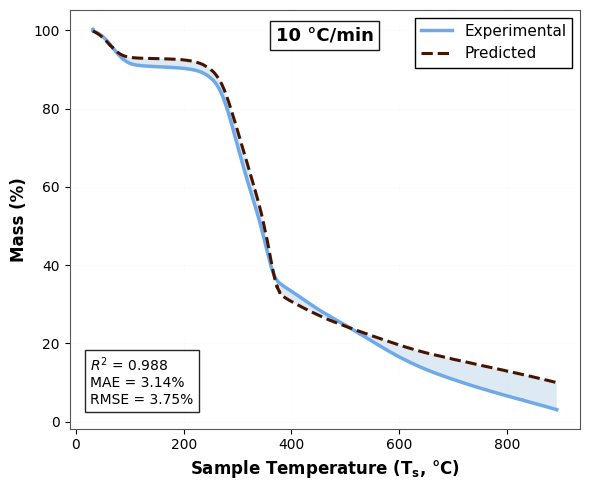

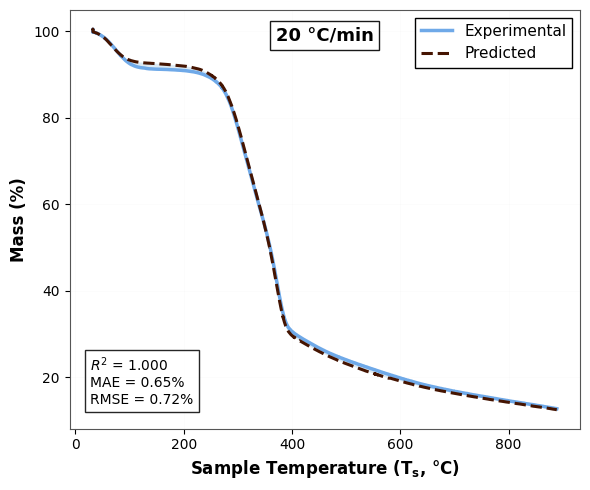

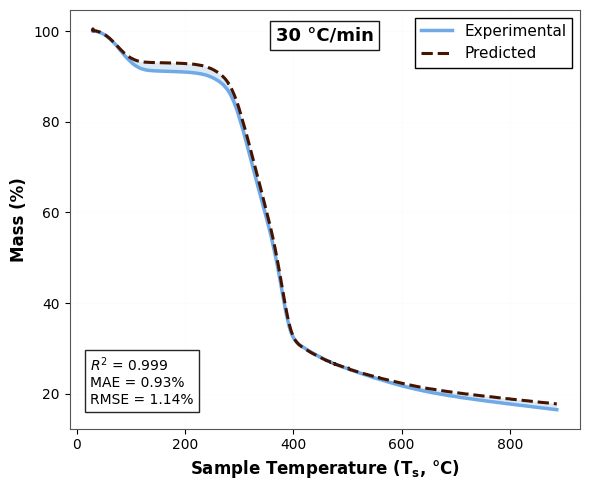

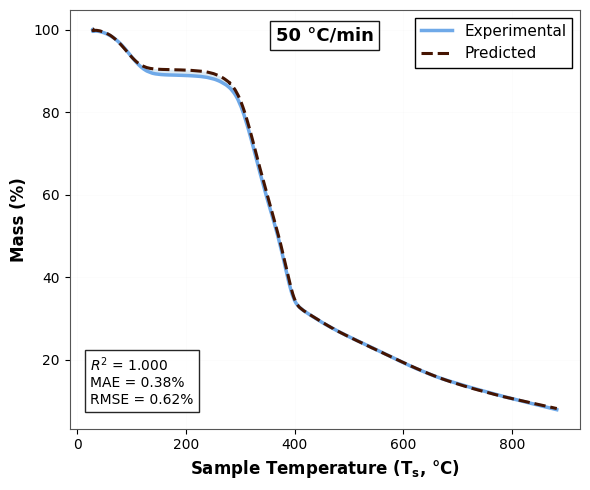

In [12]:
for rate in heating_rates:
    fig, a = plt.subplots(figsize=(6, 5))

    df = load_tga_file(TEST_SIZE, rate)
    Xp = df[['Ts', 'size', 'heating_rate']]
    yp = best_model_instance.predict(Xp)
    ye, T = df['mass_percent'].values, df['Ts'].values 

    a.plot(T, ye, lw=2.5, label='Experimental', color=BERLIN_CMAP(_berlin_vals[0]))
    a.plot(T, yp, '--', lw=2.2, label='Predicted', color=BERLIN_CMAP(_berlin_vals[2]))
    a.fill_between(T, ye, yp, alpha=.15)

    a.legend(loc='upper right', frameon=True, fancybox=False,
             edgecolor='black', facecolor='white', framealpha=1, fontsize=11)

    r2, mae = r2_score(ye, yp), mean_absolute_error(ye, yp)
    rmse = np.sqrt(mean_squared_error(ye, yp))

    a.text(.04, .06, f'$R^2$ = {r2:.3f}\nMAE = {mae:.2f}%\nRMSE = {rmse:.2f}%',
           transform=a.transAxes, fontsize=10,
           bbox=dict(facecolor='white', alpha=.85, edgecolor='black'))

    a.text(.5, .96, f'{rate} °C/min', transform=a.transAxes,
           fontsize=13, fontweight='bold', ha='center', va='top',
           bbox=dict(facecolor='white', alpha=.9, edgecolor='black', pad=4))

    a.set_xlabel(r"Sample Temperature ($\mathbf{T_s}$, °C)",
                 fontsize=12, fontweight='bold')
    a.set_ylabel('Mass (%)', fontsize=12, fontweight='bold')
    a.grid(alpha=.03)

    plt.tight_layout()
    plt.show()
    plt.close()

### Export Predicted files

In [13]:
initial_weight_assumed = 10.0

OUTPUT_PATH = os.path.join(os.path.dirname(DATA_PATH), "Files")
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Nearest training size to the held-out w5 -- used to source the Ts grid
# for the exported prediction (same idea as guava anchoring on its
# nearest training size, 600 um, when exporting predictions for 400 um)
ANCHOR_SIZE = 'w4'

for rate in heating_rates:

    Ts_real = train_data[
        (train_data['size'] == SIZE_MAP[ANCHOR_SIZE]) &
        (train_data['heating_rate'] == rate)
    ]['Ts'].values

    if len(Ts_real) == 0:
        continue

    X_pred = pd.DataFrame({
        'Ts': Ts_real,
        'size': SIZE_MAP[TEST_SIZE],
        'heating_rate': rate
    })[features]

    predicted_mass_percent = best_model_instance.predict(X_pred)

    Weight = predicted_mass_percent / 100 * initial_weight_assumed
    Time = (Ts_real - Ts_real[0]) * 60 / rate
    HF = np.zeros_like(Ts_real)
    Program_Temperature = Ts_real

    export_df = pd.DataFrame({
        'Time': Time,
        'Sample Temperature': Ts_real,
        'Unsubtracted Weight': Weight,
        'Program Temperature': Program_Temperature,
        'Unsubtracted Heat Flow': HF,
    })

    filename = os.path.join(OUTPUT_PATH, f"predicted_LOGO_withoutFE_{TEST_SIZE}-{rate}.csv")
    export_df.to_csv(filename, index=False)
    print(f"Wrote {filename}  ({len(export_df)} rows)")

print("\nPipeline execution completed successfully.")

Wrote C:\Users\SONALIKA\Downloads\WSB_TGA_data\WSB_TGA_data\Files\predicted_LOGO_withoutFE_w5-10.csv  (8260 rows)
Wrote C:\Users\SONALIKA\Downloads\WSB_TGA_data\WSB_TGA_data\Files\predicted_LOGO_withoutFE_w5-20.csv  (8260 rows)
Wrote C:\Users\SONALIKA\Downloads\WSB_TGA_data\WSB_TGA_data\Files\predicted_LOGO_withoutFE_w5-30.csv  (8260 rows)
Wrote C:\Users\SONALIKA\Downloads\WSB_TGA_data\WSB_TGA_data\Files\predicted_LOGO_withoutFE_w5-50.csv  (8260 rows)

Pipeline execution completed successfully.
